In [ ]:
# Purpose:
#   Refine CD4 T-cell subtypes from an integrated PBMC scRNA-seq dataset.
#   Use clustering, cell-cycle state, and Azimuth predictions to define
#   level-3 CD4 T-cell populations (Naive, Central Memory, Effector Memory,
#   Cytotoxic CD4, and Tregs), followed by marker discovery and validation.
#
# Steps:
#   - Load Harmony-integrated CD4 T-cell Seurat object
#   - Perform cell-cycle scoring and visualize QC metrics
#   - Assign high-confidence subtypes directly for clearly separated clusters
#   - Recluster ambiguous CD4 T-cell populations at higher resolution
#   - Define level-3 CD4 T-cell identities based on cluster structure
#   - Save finalized annotated CD4 T-cell object and marker tables

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

# Load

In [4]:
celltype = 'CD4 T'

In [5]:
obj = qs::qread(glue("data/03_cleandata/itg_{celltype}.qs"))
obj

An object of class Seurat 
28202 features across 168410 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
exp.mat <- read.table(
    file = "data/geneset/nestorawa_forcellcycle_expressionMatrix.txt",
    header = TRUE, as.is = TRUE, row.names = 1)

s.genes <- cc.genes$s.genes
g2m.genes <- cc.genes$g2m.genes

In [7]:
obj <- CellCycleScoring(obj, 
                        s.features = s.genes, 
                        g2m.features = g2m.genes, 
                        set.ident = TRUE)


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# Annotate

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



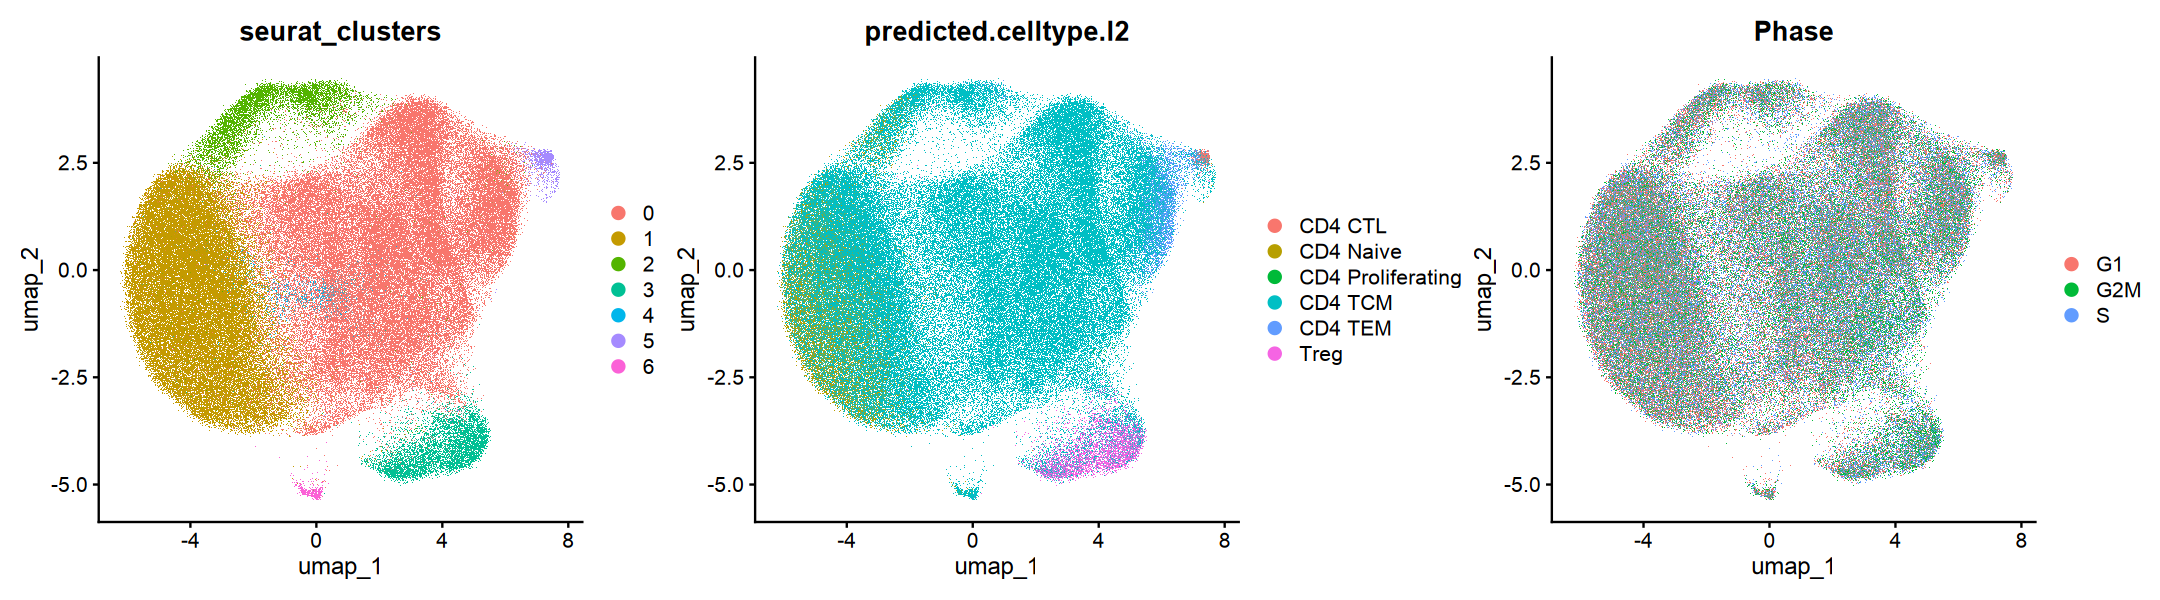

In [15]:
options(repr.plot.width=18, repr.plot.height=5)


DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2','Phase'),
        ncol=3
       )

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



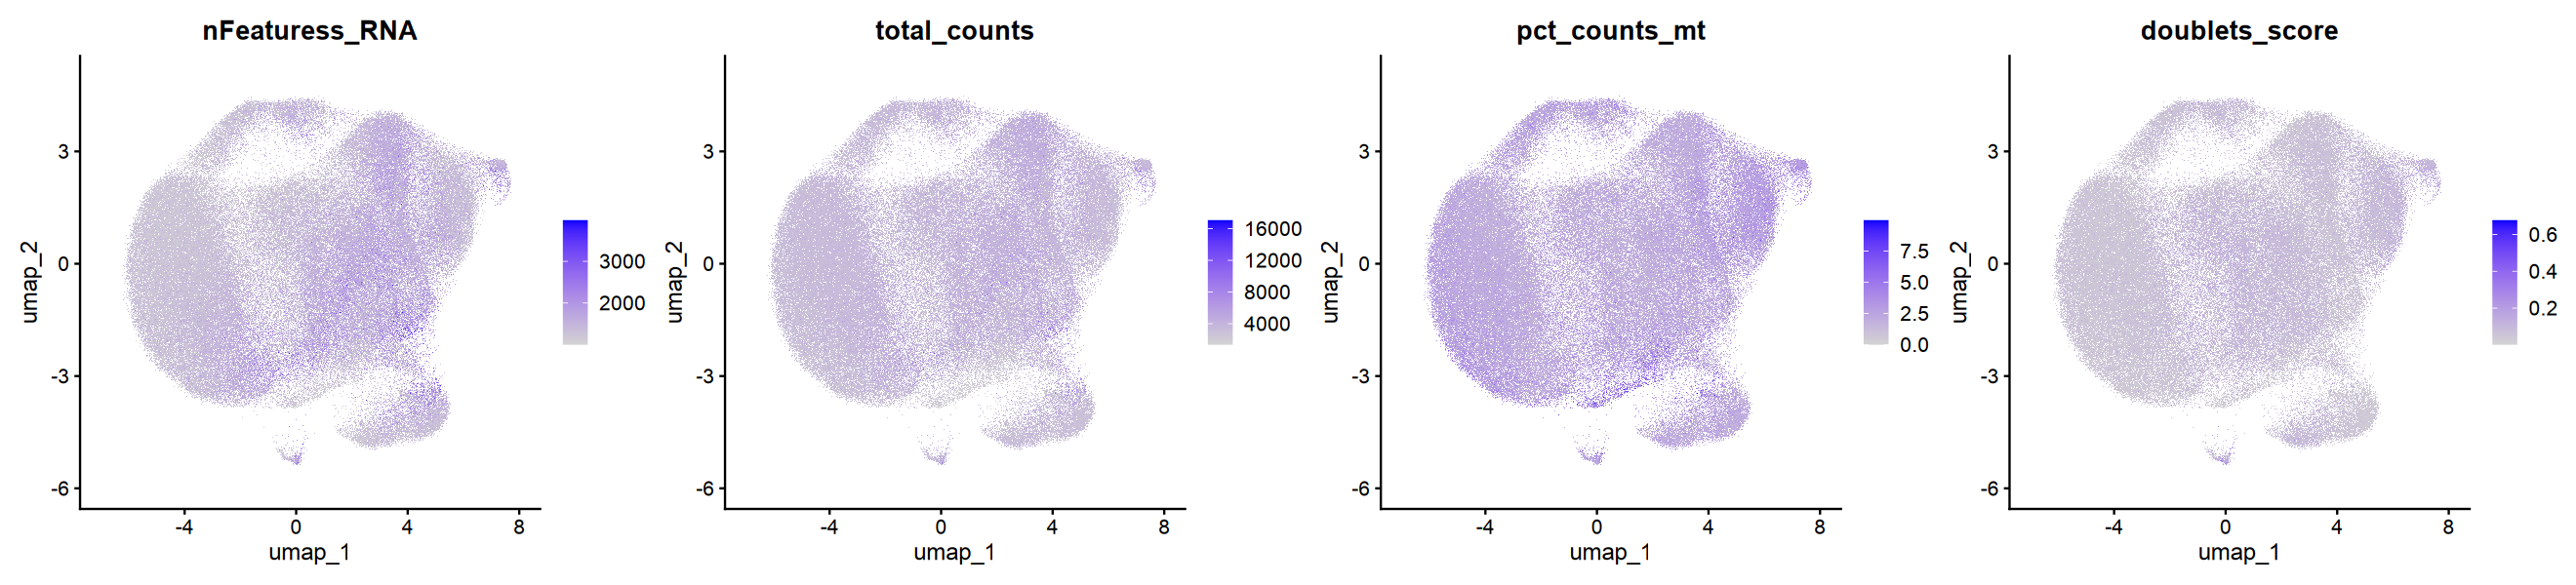

In [9]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



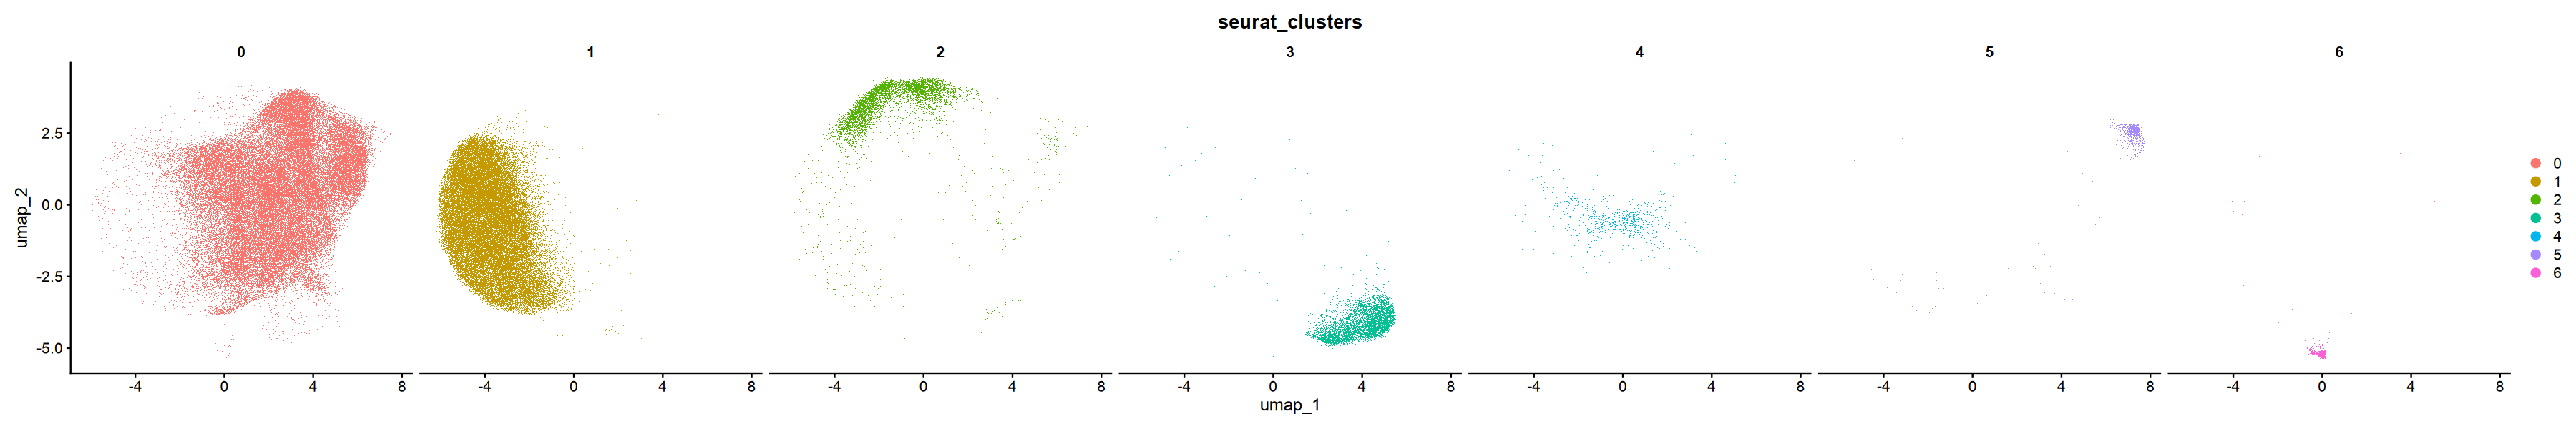

In [11]:
options(repr.plot.width=30, repr.plot.height=5)

varname = 'seurat_clusters'
DimPlot(obj, reduction = "umap",  
        group.by = varname,
        split.by = varname)

In [36]:
anno1 = obj@meta.data[,c('Phase','seurat_clusters')]

anno1 <- anno1 %>%
  mutate(celltype_level3 = case_when(
    seurat_clusters == 1 ~ "Naive CD4T",
    seurat_clusters == 3 ~ "Treg",
    seurat_clusters == 5 ~ "Cytotoxic CD4T",
    TRUE ~ "-1"
  ))

anno1 = anno %>% filter(celltype_level3 != '-1')
anno1

,Phase,seurat_clusters,celltype_level3
,<chr>,<fct>,<chr>
Pool137_10_AAACCTGAGACTCGGA-1,G1,1,Naive CD4T
Pool137_10_AAACCTGAGCTGCGAA-1,G2M,1,Naive CD4T
Pool137_10_AAACCTGGTAGGACAC-1,S,1,Naive CD4T
Pool137_10_AAACCTGGTTCCACAA-1,G1,1,Naive CD4T
Pool137_10_AAACGGGCACACGCTG-1,S,5,Cytotoxic CD4T
Pool137_10_AAACGGGCATATACGC-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAAAGACACTAA-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAAAGATCCGAG-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAACATAGGATA-1,G2M,1,Naive CD4T


In [22]:
ft = subset(obj, seurat_clusters %in% c(0,2,4,6))

ft

An object of class Seurat 
28202 features across 98115 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 98115
Number of edges: 1692222

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8692
Number of communities: 10
Elapsed time: 22 seconds


Warning message:
“Adding a command log without an assay associated with it”


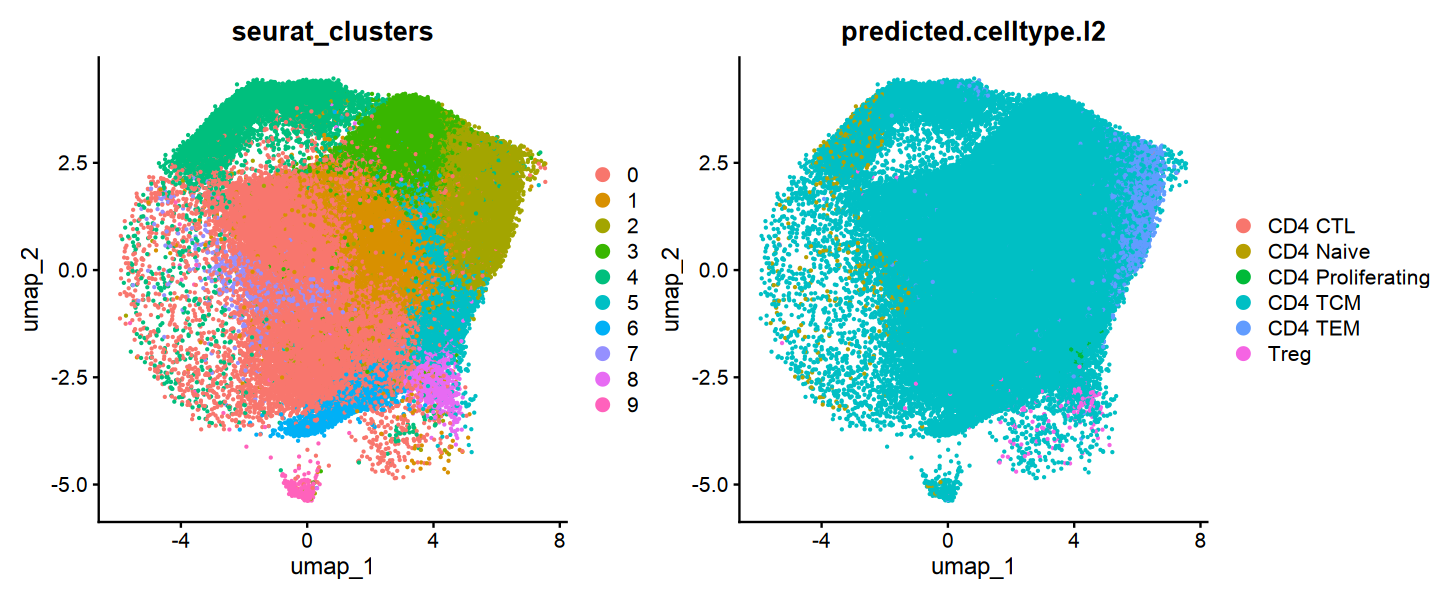

In [29]:
options(repr.plot.width=12, repr.plot.height=5)

ft <- FindClusters(ft, resolution = .3)

DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        pt.size = .001,
        ncol=2
       )

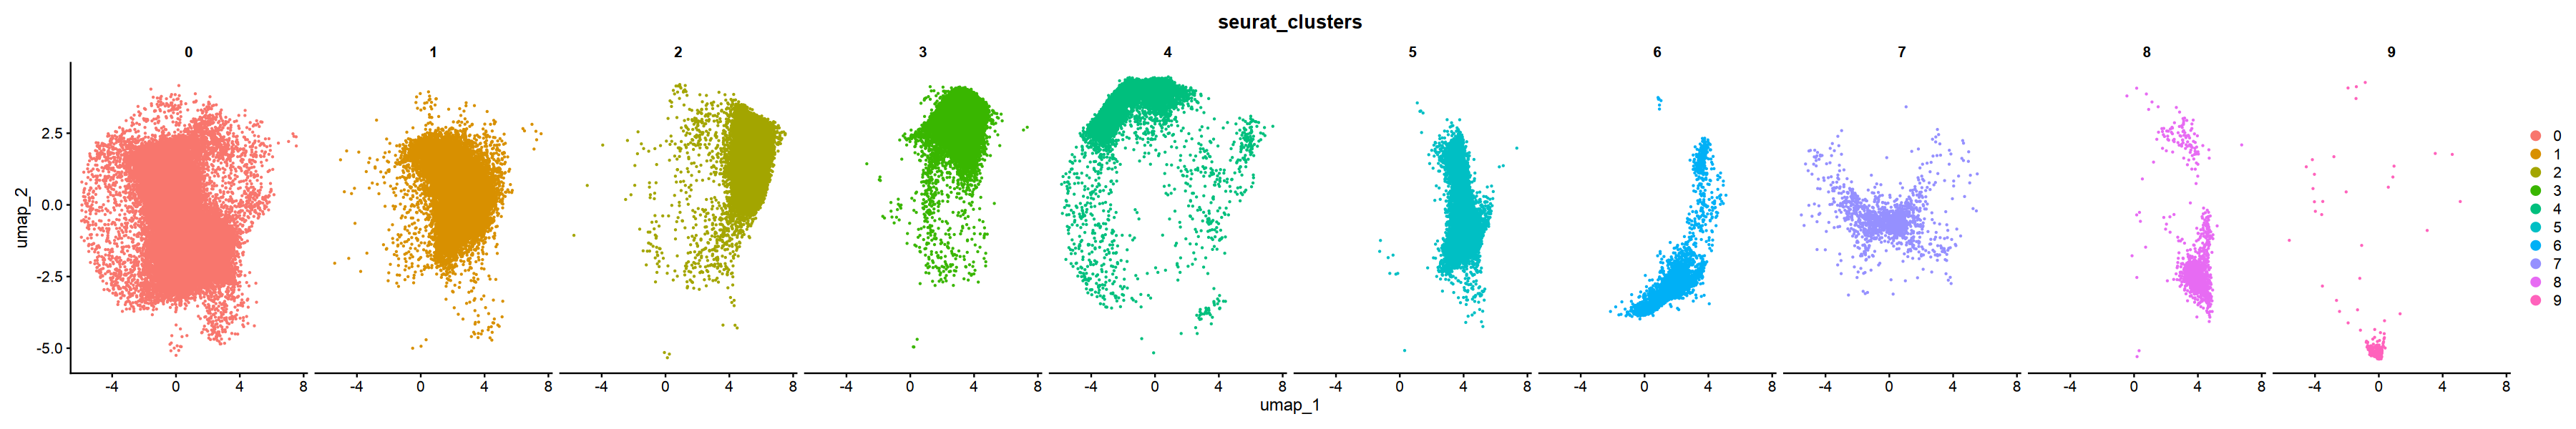

In [32]:
options(repr.plot.width=30, repr.plot.height=5)

varname = 'seurat_clusters'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname
        
       )

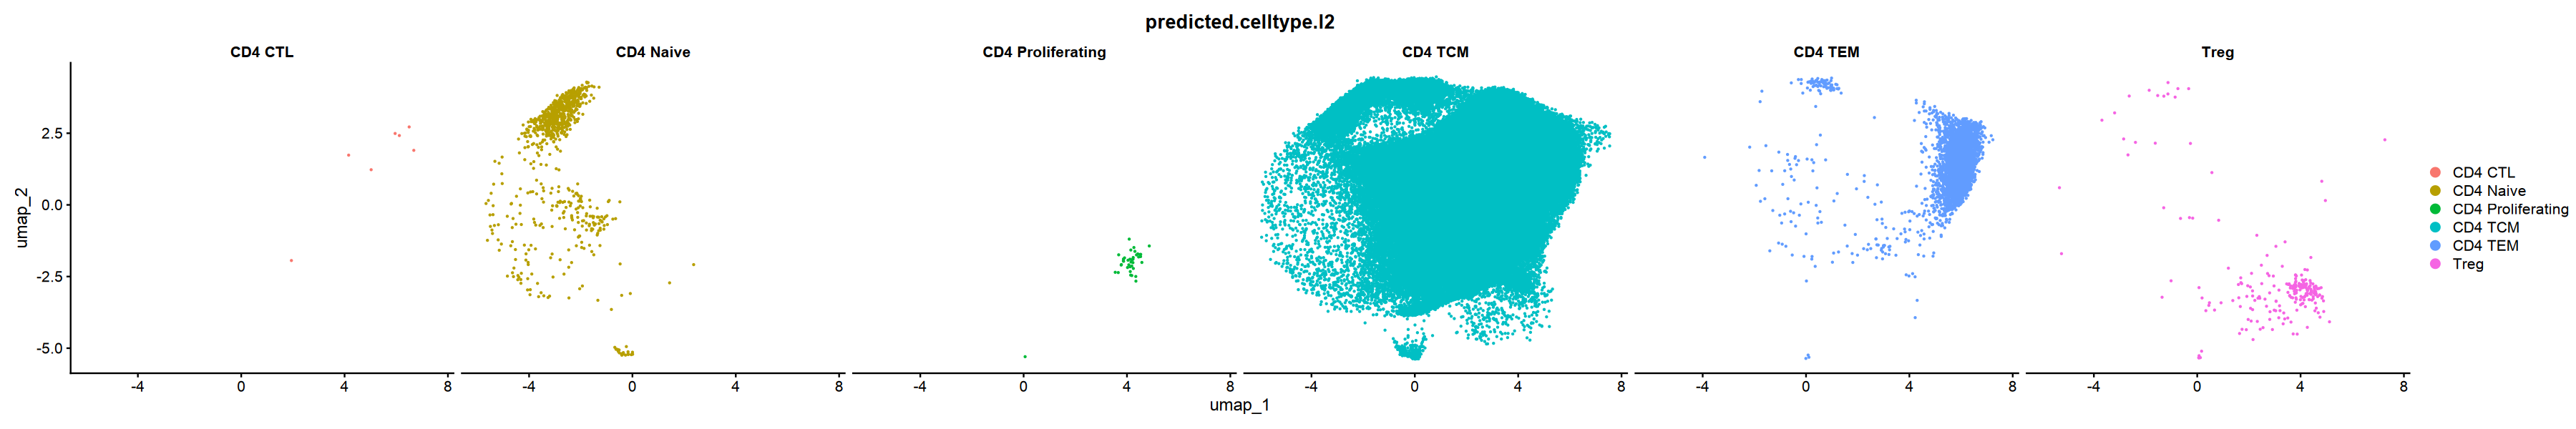

In [33]:
options(repr.plot.width=30, repr.plot.height=5)

varname = 'predicted.celltype.l2'
DimPlot(ft, reduction = "umap",  
        group.by = varname,
        split.by = varname
        
       )

In [35]:
anno2 <- ft@meta.data[,c('Phase','seurat_clusters')] %>%
  mutate(celltype_level3 = case_when(
    seurat_clusters == 2 ~ "Effector Memory CD4T",
    TRUE ~ "Central Memory CD4T"
  ))

anno2

,Phase,seurat_clusters,celltype_level3
,<chr>,<fct>,<chr>
Pool137_10_AAACCTGCAGGAATCG-1,S,0,Central Memory CD4T
Pool137_10_AAACCTGGTACGAAAT-1,G2M,1,Central Memory CD4T
Pool137_10_AAACCTGGTAGTACCT-1,G1,1,Central Memory CD4T
Pool137_10_AAACCTGGTGAACCTT-1,G1,0,Central Memory CD4T
Pool137_10_AAACCTGTCATCGGAT-1,G2M,5,Central Memory CD4T
Pool137_10_AAACCTGTCTCGTTTA-1,G1,4,Central Memory CD4T
Pool137_10_AAACGGGAGCAGGTCA-1,G2M,3,Central Memory CD4T
Pool137_10_AAACGGGCATGGTAGG-1,G1,0,Central Memory CD4T
Pool137_10_AAACGGGGTACTTAGC-1,G1,0,Central Memory CD4T


In [37]:
anno = rbind(anno1, anno2)
anno

,Phase,seurat_clusters,celltype_level3
,<chr>,<fct>,<chr>
Pool137_10_AAACCTGAGACTCGGA-1,G1,1,Naive CD4T
Pool137_10_AAACCTGAGCTGCGAA-1,G2M,1,Naive CD4T
Pool137_10_AAACCTGGTAGGACAC-1,S,1,Naive CD4T
Pool137_10_AAACCTGGTTCCACAA-1,G1,1,Naive CD4T
Pool137_10_AAACGGGCACACGCTG-1,S,5,Cytotoxic CD4T
Pool137_10_AAACGGGCATATACGC-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAAAGACACTAA-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAAAGATCCGAG-1,G2M,1,Naive CD4T
Pool137_10_AAAGCAACATAGGATA-1,G2M,1,Naive CD4T


In [40]:
dim(obj)

[1]  27879 168410

In [42]:
# keep only cells present in the Seurat object
common <- intersect(rownames(anno), colnames(obj))
print(length(common))

# make a named vector aligned by barcode
vec <- anno[common, "celltype_level3", drop = TRUE]
names(vec) <- common

# add to metadata (cells without value become NA)
obj <- AddMetaData(obj, metadata = vec, col.name = "celltype_level3")

[1] 168410


Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”


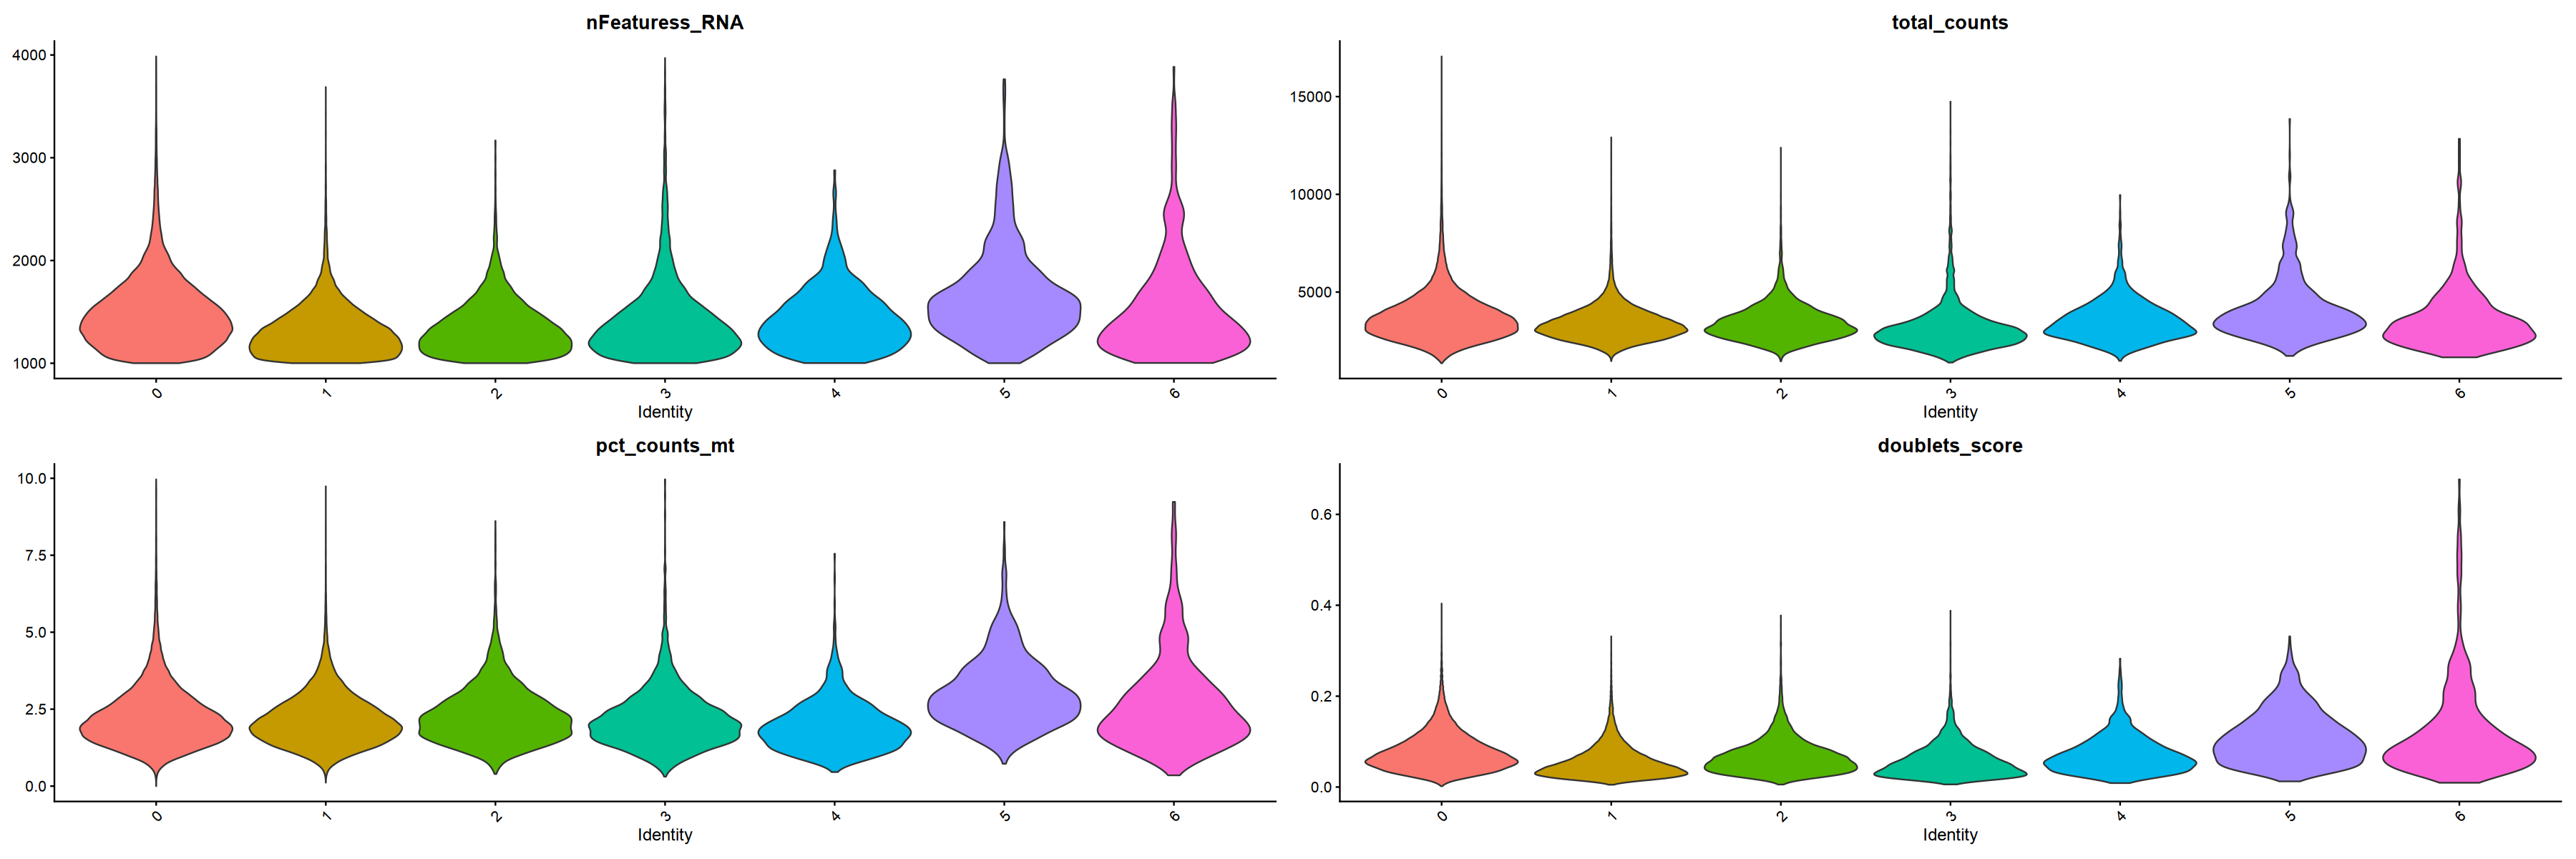

In [11]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

## Save

In [48]:
celltype = 'CD4 T'

qs::qsave(obj, glue('data/03_cleandata/ft_{celltype}.qs'))